# Lesson 4 · Smoothing Forecasters: Moving Average, SES, Holt & Holt-Winters
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 14** &nbsp;|&nbsp; ⏱ ≈ 100 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Explain **moving average** forecasts and the window-length trade-off
> - Implement **simple exponential smoothing (SES)** by hand and with `statsmodels`
> - Use **Holt's linear trend** (with and without damping) for trending data
> - Use the **Holt-Winters** seasonal method (additive vs multiplicative)
> - Compare smoothing models fairly with walk-forward evaluation

**Prerequisites:** Lessons 1 and 3 (components; metrics, baselines, walk-forward).

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · The big idea: forecasting = smart averaging of the past

Suppose you're asked: *"What will maize cost next week?"* Natural instincts:
- "About what it cost last week." → **naive**
- "Average of the last month." → **moving average**
- "Mostly recent weeks, but still some memory of older ones." → **exponential smoothing**

Exponential smoothing is the last instinct made precise. It is also the workhorse behind countless production forecasts in supply chains and retail: simple, fast, interpretable, and shockingly hard to beat.

> 🎯 **Roadmap:** Moving Average → Simple Exp. Smoothing (level) → Holt (level + trend) → Holt-Winters (level + trend + seasonality). Each step adds one more "ingredient" from Lesson 1.

## 2 · Moving average (MA)

A **moving average of order *w*** averages the last *w* observations:

$$\hat y_{t+1} = \frac{1}{w}\sum_{k=0}^{w-1} y_{t-k}$$

It has **two distinct uses**: don't confuse them:

| Use | Window | Purpose |
|---|---|---|
| **Smoothing** (descriptive) | often *centred* | reveal the trend in a chart (peeks at the future; fine for plots) |
| **Forecasting** | always *trailing* | flat forecast at the recent average |

**Trade-off:** short window = reacts fast but noisy; long window = smooth but **lags** a trend.

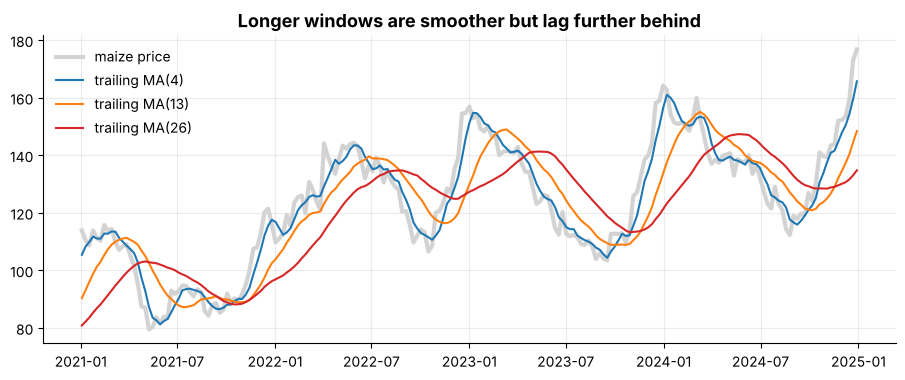

In [2]:
maize = load_weekly("maize")["price"]
fig, ax = plt.subplots()
ax.plot(maize.loc["2021":], color="lightgray", lw=3, label="maize price")
for w, c in [(4, "tab:blue"), (13, "tab:orange"), (26, "tab:red")]:
    ax.plot(maize.rolling(w).mean().loc["2021":], color=c, label=f"trailing MA({w})")
ax.legend(); ax.set_title("Longer windows are smoother but lag further behind"); plt.show()

> 💡 **Notice the lag.** In an uptrend every trailing MA is *below* the price, and the longer the window the bigger the gap. A MA *forecast* inherits this bias.
>
> The forecast from a MA is **flat** (one number for every future step): it cannot extrapolate a trend or a season.

## 3 · Simple Exponential Smoothing (SES)

Why should last week and 7 weeks ago count equally? Exponential smoothing **weights recent observations more**, with weights that decay geometrically:

$$\ell_t = \alpha\, y_t + (1-\alpha)\,\ell_{t-1} \qquad\qquad \hat y_{t+h} = \ell_t$$

- $\ell_t$ is the **level**: our running estimate of "where the series is right now".
- $\alpha \in (0,1]$ is the **smoothing parameter**: large α → trust the newest data (fast reaction); small α → trust history (stable).
- $\alpha = 1$ is exactly the **naive** forecast; $\alpha \to 0$ approaches the overall mean.

Unrolling the recursion: the weight on the observation *k* steps back is $\alpha(1-\alpha)^k$: hence **"exponential"**.

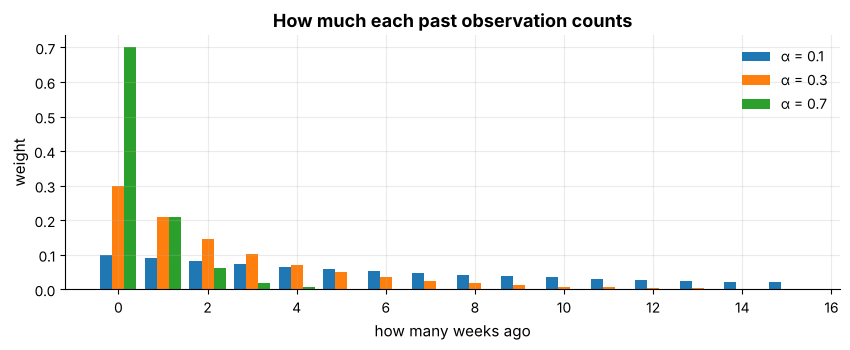

In [3]:
k = np.arange(0, 16)
fig, ax = plt.subplots(figsize=(10, 3.3))
for a, off in [(0.1, -0.27), (0.3, 0), (0.7, 0.27)]:
    ax.bar(k + off, a * (1 - a) ** k, width=0.27, label=f"α = {a}")
ax.set_xlabel("how many weeks ago"); ax.set_ylabel("weight"); ax.set_title("How much each past observation counts"); ax.legend(); plt.show()

### Build it yourself (it's three lines)

In [4]:
def ses_levels(y, alpha, level0=None):
    level = y[0] if level0 is None else level0
    levels = [level]
    for obs in y[1:]:
        level = alpha * obs + (1 - alpha) * level
        levels.append(level)
    return np.array(levels)

y = maize.values
for a in (0.1, 0.5, 0.9):
    print(f"alpha={a}: forecast for every future week = {ses_levels(y, a)[-1]:.2f}")
print("last observed price:", y[-1])

alpha=0.1: forecast for every future week = 146.61
alpha=0.5: forecast for every future week = 170.53
alpha=0.9: forecast for every future week = 176.25
last observed price: 176.76


Now let `statsmodels` **estimate α** for us (it minimises the squared one-step-ahead errors):

In [5]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

h = 26
train, test = maize.iloc[:-h], maize.iloc[-h:]
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
print(f"Estimated alpha = {ses.params['smoothing_level']:.3f}")

Estimated alpha = 1.000


> 🔎 **Interpretation:** α is almost **1**. The data are telling us "the best predictor of next week is essentially *this* week": the signature of a **random-walk-like** price.
> This is common in markets: prices already contain most available information. It also warns us that simple smoothing can at best *match* naive here; to do better we need **trend** and **seasonality** or **outside information** (rainfall, fuel).

## 4 · Holt's linear trend method

SES forecasts a flat line, so it systematically lags in a trend. **Holt** adds a second state, the **trend (slope)** $b_t$:

$$\ell_t = \alpha y_t + (1-\alpha)(\ell_{t-1}+b_{t-1})\qquad b_t = \beta(\ell_t-\ell_{t-1}) + (1-\beta)b_{t-1}\qquad \hat y_{t+h} = \ell_t + h\,b_t$$

| Parameter | Controls |
|---|---|
| α (`smoothing_level`) | how fast the **level** adapts |
| β (`smoothing_trend`) | how fast the **slope** adapts |
| φ (`damping_trend`) | in the **damped** version, $\hat y_{t+h}=\ell_t+(\phi+\phi^2+\dots+\phi^h)b_t$: the trend *flattens out* |

> ⚠️ **Undamped Holt extrapolates the slope forever.** Over a 6-month horizon that's usually silly (nothing grows linearly for ever). **Damped trend** is the safer default and wins many forecasting competitions.

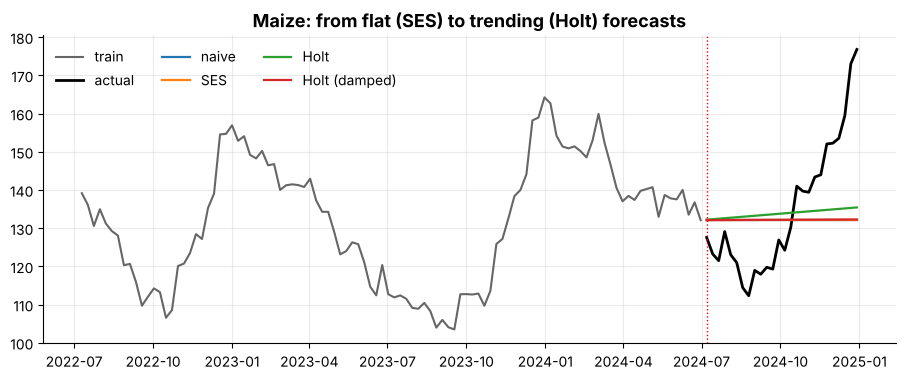

{'smoothing_level': 1.0, 'smoothing_trend': 0.0}


,MAE,RMSE,MAPE,sMAPE,MASE
Holt,13.817,16.613,10.006,10.094,5.526
Holt (damped),14.335,17.546,10.251,10.475,5.733
SES,14.364,17.604,10.264,10.496,5.744
naive,14.364,17.604,10.264,10.496,5.744


In [6]:
holt = Holt(train, initialization_method="estimated").fit()
damped = Holt(train, damped_trend=True, initialization_method="estimated").fit()
fcs = {"naive": fc_naive(train, h), "SES": ses.forecast(h).values, "Holt": holt.forecast(h).values, "Holt (damped)": damped.forecast(h).values}
plot_forecasts(train, test, fcs, "Maize: from flat (SES) to trending (Holt) forecasts"); plt.show()
print({k: round(float(v), 3) for k, v in holt.params.items() if k in ("smoothing_level", "smoothing_trend")})
score_table(test, fcs, y_train=train)

## 5 · Holt-Winters: adding seasonality

**Holt-Winters** adds a third state: a **seasonal** component $s_t$ for each position in the season of length $m$ ($m=12$ for monthly, $m=52$ for weekly).

| Variant | Model | Use when |
|---|---|---|
| **Additive** seasonality | $\hat y_{t+h} = \ell_t + b_t h + s_{t+h-m}$ | seasonal swing has constant **size** |
| **Multiplicative** seasonality | $\hat y_{t+h} = (\ell_t + b_t h)\times s_{t+h-m}$ | swing is a **percentage** of the level (grows with the series) |

Rule of thumb from Lesson 1: if the seasonal wiggle gets taller as the series rises → **multiplicative**. (If unsure, try both; or log-transform and use additive.)

### The classic: airline passengers 1949–1960

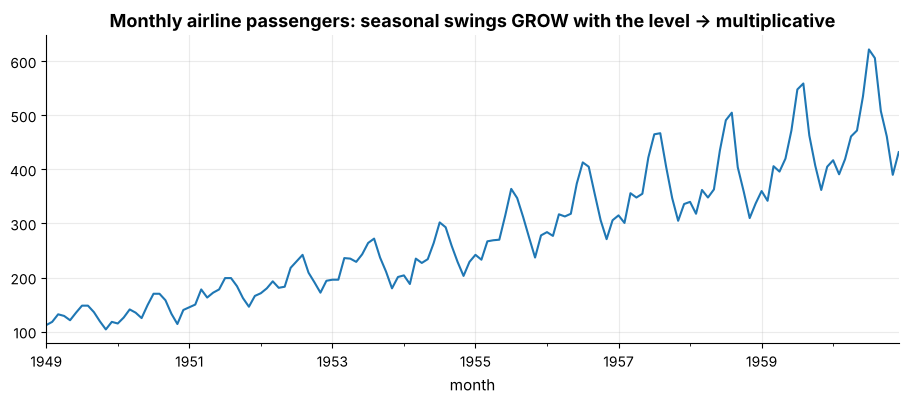

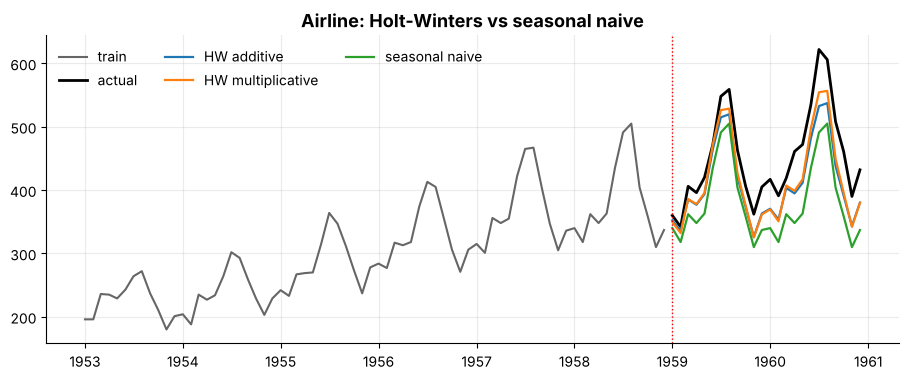

,MAE,RMSE,MAPE,sMAPE,MASE
HW multiplicative,36.515,40.997,8.012,8.430,1.278
HW additive,41.198,46.616,8.855,9.359,1.442
seasonal naive,71.250,76.995,15.523,17.013,2.494


In [7]:
air = load_airline()
a_train, a_test = air.iloc[:-24], air.iloc[-24:]
air.plot(title="Monthly airline passengers: seasonal swings GROW with the level → multiplicative"); plt.show()

hw_add = ExponentialSmoothing(a_train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12, initialization_method="estimated").fit()
hw_mul = ExponentialSmoothing(a_train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12, initialization_method="estimated").fit()
fcs = {"HW additive": hw_add.forecast(24).values, "HW multiplicative": hw_mul.forecast(24).values, "seasonal naive": fc_snaive(a_train, 24, m=12)}
plot_forecasts(a_train, a_test, fcs, "Airline: Holt-Winters vs seasonal naive", last_train=72); plt.show()
score_table(a_test, fcs, y_train=a_train, m=12)

### Prediction intervals: a forecast without uncertainty is just a guess

A point forecast of 450 is far less useful than "450, and 80 % sure it's between 410 and 490". `statsmodels` offers state-space exponential smoothing (`ETSModel`) with built-in intervals:

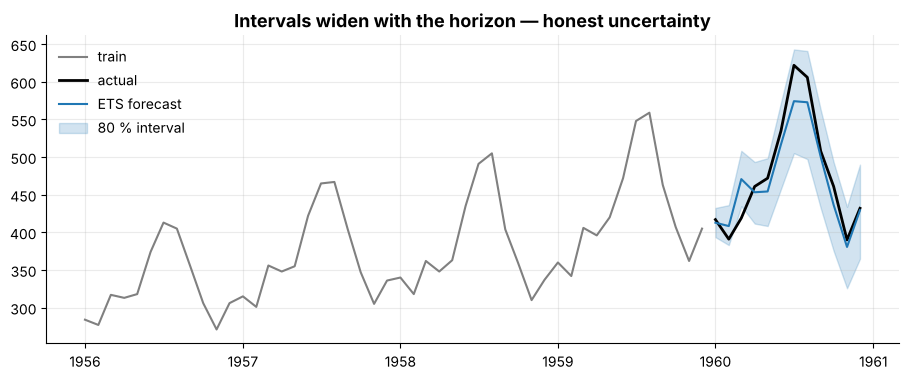

Share of actual values inside the nominal 80 % band: 92%


In [8]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
b_train, b_test = air.iloc[:-12], air.iloc[-12:]                 # hold out the final 12 months
ets = ETSModel(b_train, error="mul", trend="add", seasonal="mul", seasonal_periods=12).fit(disp=False)
pred = ets.get_prediction(start=b_test.index[0], end=b_test.index[-1]).summary_frame(alpha=0.2)     # 80 % interval

fig, ax = plt.subplots()
ax.plot(b_train.iloc[-48:], color="gray", label="train"); ax.plot(b_test, color="black", lw=2, label="actual")
ax.plot(pred["mean"], color="tab:blue", label="ETS forecast")
ax.fill_between(pred.index, pred["pi_lower"], pred["pi_upper"], color="tab:blue", alpha=0.2, label="80 % interval")
ax.legend(); ax.set_title("Intervals widen with the horizon; honest uncertainty"); plt.show()
inside = ((b_test.values >= pred["pi_lower"].values) & (b_test.values <= pred["pi_upper"].values)).mean()
print(f"Share of actual values inside the nominal 80 % band: {inside:.0%}")

> ⚠️ **Never trust an interval blindly.** A good 80 % band should contain about 80 % of future actuals (this is called **coverage**). Twelve points can't prove calibration, and intervals assume the model's structure is right:
> when the world changes (a drought!) they are too narrow. Check coverage across many walk-forward origins before promising anyone "80 % confidence".

## 6 · Weekly data with a 52-week season

Weekly seasonality (m = 52) means 52 seasonal parameters to estimate from only ~12 years, which is demanding. Practical advice:
- Use `initialization_method="heuristic"` for speed and stability;
- Prefer **damped** trend;
- Consider aggregating to **monthly** (m = 12) if the decision doesn't need weekly detail;
- Or use **Fourier terms** (a few sines/cosines) in a regression or SARIMAX instead (Lesson 5).

### 🏁 Tournament: walk-forward on weekly maize (h = 12)

In [9]:
s = load_weekly("maize")["price"]
models = {
    "naive":               fc_naive,
    "moving avg (4)":      lambda tr, h: fc_ma(tr, h, 4),
    "SES":                 fc_ses,
    "Holt (damped)":       fc_holt,
    "Holt-Winters (mul, damped)": lambda tr, h: fc_hw(tr, h, m=52, seasonal="mul"),
}
res = {name: walk_forward(s, f, initial=470, horizon=12, step=4) for name, f in models.items()}
tab = pd.DataFrame({n: {"MAE": mae(w.actual, w.forecast), "RMSE": rmse(w.actual, w.forecast)} for n, w in res.items()}).T
tab["skill vs naive"] = 1 - tab["RMSE"] / tab.loc["naive", "RMSE"]
tab.round(3).sort_values("RMSE")

,MAE,RMSE,skill vs naive
"Holt-Winters (mul, damped)",8.261,11.456,0.254
naive,11.935,15.361,0.000
SES,11.936,15.361,-0.000
Holt (damped),12.223,15.713,-0.023
moving avg (4),13.208,16.818,-0.095


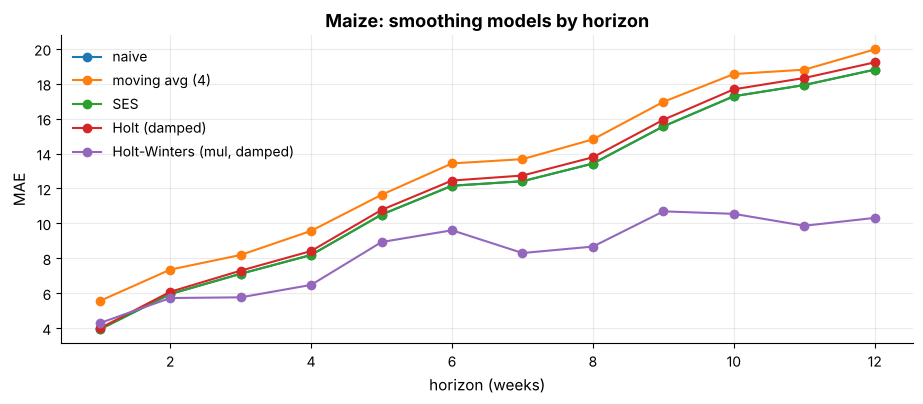

In [10]:
fig, ax = plt.subplots()
for name, w in res.items():
    bh = scores_by_horizon(w); ax.plot(bh.index, bh["MAE"], marker="o", label=name)
ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("MAE"); ax.legend(); ax.set_title("Maize: smoothing models by horizon"); plt.show()

### 🧠 Reading the tournament
- Pure level/trend smoothing models (SES, damped Holt, moving average) **tie with or lose to naive**: the price is nearly a random walk, consistent with α ≈ 1.
- **Holt-Winters**, which also captures the *annual seasonality*, is the clear winner (roughly 25 % lower RMSE than naive at 1–12 weeks ahead): the seasonal shape is genuinely predictable information that naive ignores.
- This is the key lesson of Phase 7: *"fancier" does not automatically mean better: the evaluation decides.*

## 🧩 Practice problems

### 🧩 Problem 4.1 · Simple exponential smoothing by hand  ·  🟢 Easy

Implement SES with a `for` loop: `level = alpha*y_t + (1-alpha)*level`, starting with `level = y[0]`.
  For `y = [3, 5, 9, 20, 12, 17, 22, 23, 51, 41]` and `alpha = 0.3`, what is the **forecast for the next period**? Store it in `my_forecast`.
  Then verify against `statsmodels`.

<details><summary>💡 Hint 1</summary>

The forecast for *any* future step is the last level; SES gives a flat forecast.

</details>

<details><summary>💡 Hint 2</summary>

Loop from the second observation (`y[1:]`).

</details>

<details><summary>💡 Hint 3</summary>

statsmodels: `SimpleExpSmoothing(y, initialization_method='known', initial_level=y[0]).fit(smoothing_level=0.3, optimized=False).forecast(1)`.

</details>

In [11]:
y = [3, 5, 9, 20, 12, 17, 22, 23, 51, 41]
alpha = 0.3
my_forecast = None
# YOUR CODE HERE
check('SES forecast', my_forecast, 31.62, tol=0.01)

⏳ SES forecast: not answered yet (replace the `None` with your answer)


### 🧩 Problem 4.2 · Moving-average window shootout  ·  🟡 Medium

Walk-forward evaluate moving-average forecasters on **maize** with windows `w ∈ {1, 2, 4, 8, 13, 26}` (horizon 4, `initial=470`, `step=2`) and print MAE for each.
  (`w = 1` is the naive forecast.) Which window wins, and what does that tell you about the series?

<details><summary>💡 Hint 1</summary>

`fc_ma(train, h, w=8)` already exists. Wrap it: `lambda tr, h, w=w: fc_ma(tr, h, w)`: the `w=w` default avoids Python's late-binding closure trap.

</details>

<details><summary>💡 Hint 2</summary>

Loop over windows, call `walk_forward(s, f, initial=470, horizon=4, step=2)`, collect `mae(wf.actual, wf.forecast)`.

</details>

<details><summary>💡 Hint 3</summary>

Think trend: with a rising series, a long window averages in stale, lower prices.

</details>

In [12]:
s = load_weekly('maize')['price']
# YOUR CODE HERE

### 🧩 Problem 4.3 · SES vs Holt vs damped Holt on rice  ·  🟡 Medium

Hold out the last 26 weeks of **rice**. Fit `SimpleExpSmoothing`, `Holt` and `Holt(damped_trend=True)` on the training part (all with `initialization_method='estimated'`).
  Plot the three 26-week forecasts and print a score table. Report the fitted `smoothing_level` (α) and `smoothing_trend` (β) of Holt. What do they say about the series?

<details><summary>💡 Hint 1</summary>

`from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt`.

</details>

<details><summary>💡 Hint 2</summary>

Fitted parameters live in `fit.params` (a dict): keys `'smoothing_level'`, `'smoothing_trend'`, `'damping_trend'`.

</details>

<details><summary>💡 Hint 3</summary>

`fit.forecast(26)` gives the forecast. Use `plot_forecasts` and `score_table` from `course_utils`.

</details>

In [13]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
s = load_weekly('rice')['price']
train, test = s.iloc[:-26], s.iloc[-26:]
# YOUR CODE HERE

### 🧩 Problem 4.4 · Additive or multiplicative? Airline passengers  ·  🟡 Medium

Using the classic airline-passenger series (`load_airline()`), hold out the last 24 months. Fit Holt-Winters (`trend='add'`, `damped_trend=True`, `seasonal_periods=12`)
  with **additive** and with **multiplicative** seasonality. Compare RMSE with the seasonal naive baseline, plot, and explain in a comment *why* one is better.

<details><summary>💡 Hint 1</summary>

`ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='add' or 'mul', seasonal_periods=12, initialization_method='estimated')`.

</details>

<details><summary>💡 Hint 2</summary>

Look at the raw plot: do the seasonal swings get bigger as the level rises?

</details>

<details><summary>💡 Hint 3</summary>

Seasonal naive for monthly data: `fc_snaive(train, 24, m=12)`.

</details>

In [14]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
air = load_airline()
train, test = air.iloc[:-24], air.iloc[-24:]
# YOUR CODE HERE

### 🧩 Problem 4.5 · Holt-Winters tournament on monthly onion prices  ·  🔴 Challenge

Resample **onion** weekly prices to monthly means (`'ME'`). Hold out the last 12 months. Fit **every** reasonable Holt-Winters configuration:
  `trend ∈ {None, 'add'}`, `damped ∈ {False, True}` (only when there is a trend), `seasonal ∈ {'add', 'mul'}` (all with `seasonal_periods=12`).
  Rank them by **AICc on the training data**, then evaluate the winner and the seasonal-naive baseline on the 12 held-out months.
  Does the model chosen by AICc also win on the test set?

<details><summary>💡 Hint 1</summary>

Loop with `itertools.product`; skip combos where `trend is None and damped`.

</details>

<details><summary>💡 Hint 2</summary>

After `fit = ExponentialSmoothing(...).fit()`, the information criterion is `fit.aicc`.

</details>

<details><summary>💡 Hint 3</summary>

Test RMSE for the AICc-best: `rmse(test, fit.forecast(12))`; compare with `fc_snaive(train, 12, m=12)`.

</details>

In [15]:
import itertools
from statsmodels.tsa.holtwinters import ExponentialSmoothing
monthly = load_weekly('onion')['price'].resample('ME').mean()
train, test = monthly.iloc[:-12], monthly.iloc[-12:]
# YOUR CODE HERE

## ✅ Recap
- **MA**: flat forecast; window length trades noise against lag.
- **SES**: exponentially decaying weights; α near 1 ⇒ random-walk-like.
- **Holt**: level + trend (use **damping** for long horizons).
- **Holt-Winters**: level + trend + season (additive for constant swings, multiplicative for proportional swings).
- Always attach **prediction intervals** when communicating forecasts, and validate with **walk-forward**, not in-sample fit.

### ⚠️ Common mistakes
1. Using undamped Holt for long horizons.
2. Picking additive seasonality when the seasonal swing grows with the level.
3. Fitting m = 52 seasonality with fewer than ~2–3 full years of data.
4. Judging models by in-sample SSE/AIC alone.

### 🔮 Next lesson
Exponential smoothing describes *level, trend, season*. **ARIMA** takes a different view: it models the **autocorrelation** itself. In **Lesson 5** you'll put your ACF/PACF skills to work to fit ARIMA, SARIMA and SARIMAX.